# CLIP ViT-L/14 서버 실험 버블차트

## tl;dr

PA-100K 서버 실험에서 CLIP ViT-L/14 fine-tune probe는 77.91%를 관측했지만, 20k/5k/5k probe라 full split 실험과 직접 우열 비교하지 않는다. 이 노트북은 동일한 mA–instance IoU 축에 full split 결과와 probe 관측값을 함께 표시한다.

## Context & Methods

- 입력: `experiments/results/clip_vitl14_server_bubble_data.json`
- x축: PA-100K test mA(%)
- y축: PA-100K test instance IoU(%)
- 버블 면적: train rows에 비례
- 세로선: mA 85% 목표
- fine-tune probe는 20k/5k/5k라서 80k/10k/10k 실험과 직접 동률 비교하지 않는다.

이 지표는 CCTV identity/track-heldout 정확도가 아니다.

## Data

In [1]:
import json
from pathlib import Path

data_rel = Path('experiments/results/clip_vitl14_server_bubble_data.json')
candidates = [Path.cwd(), Path.cwd().parent]
project_root = next((candidate for candidate in candidates if (candidate / data_rel).exists()), Path.cwd())
data_path = project_root / 'experiments' / 'results' / 'clip_vitl14_server_bubble_data.json'
data = json.loads(data_path.read_text(encoding='utf-8'))
assert data['status'] == 'valid'
assert len(data['rows']) == 6
assert data['target_mA_pct'] == 85.0
for row in data['rows']:
    assert row['test_mA_pct'] > 0
    assert row['test_instance_iou_pct'] > 0
print('rows=', len(data['rows']))
for row in data['rows']:
    print(f"{row['label']}: mA={row['test_mA_pct']:.2f}%, IoU={row['test_instance_iou_pct']:.2f}%, status={row['status']}")

rows= 6
SOLIDER teacher head: mA=79.24%, IoU=69.86%, status=measured
CLIP ViT-L/14 fine-tune: mA=77.91%, IoU=55.12%, status=measured_probe
CLIP ViT-L/14 + SOLIDER KD: mA=71.56%, IoU=45.75%, status=measured
CLIP ViT-L/14 hard head: mA=72.12%, IoU=44.03%, status=measured
CLIP ViT-L/14 fresh full fine-tune: mA=78.24%, IoU=54.77%, status=measured_recheck
CLIP ViT-L/14 fresh SOLIDER selection: mA=73.63%, IoU=44.31%, status=measured_recheck


## Results

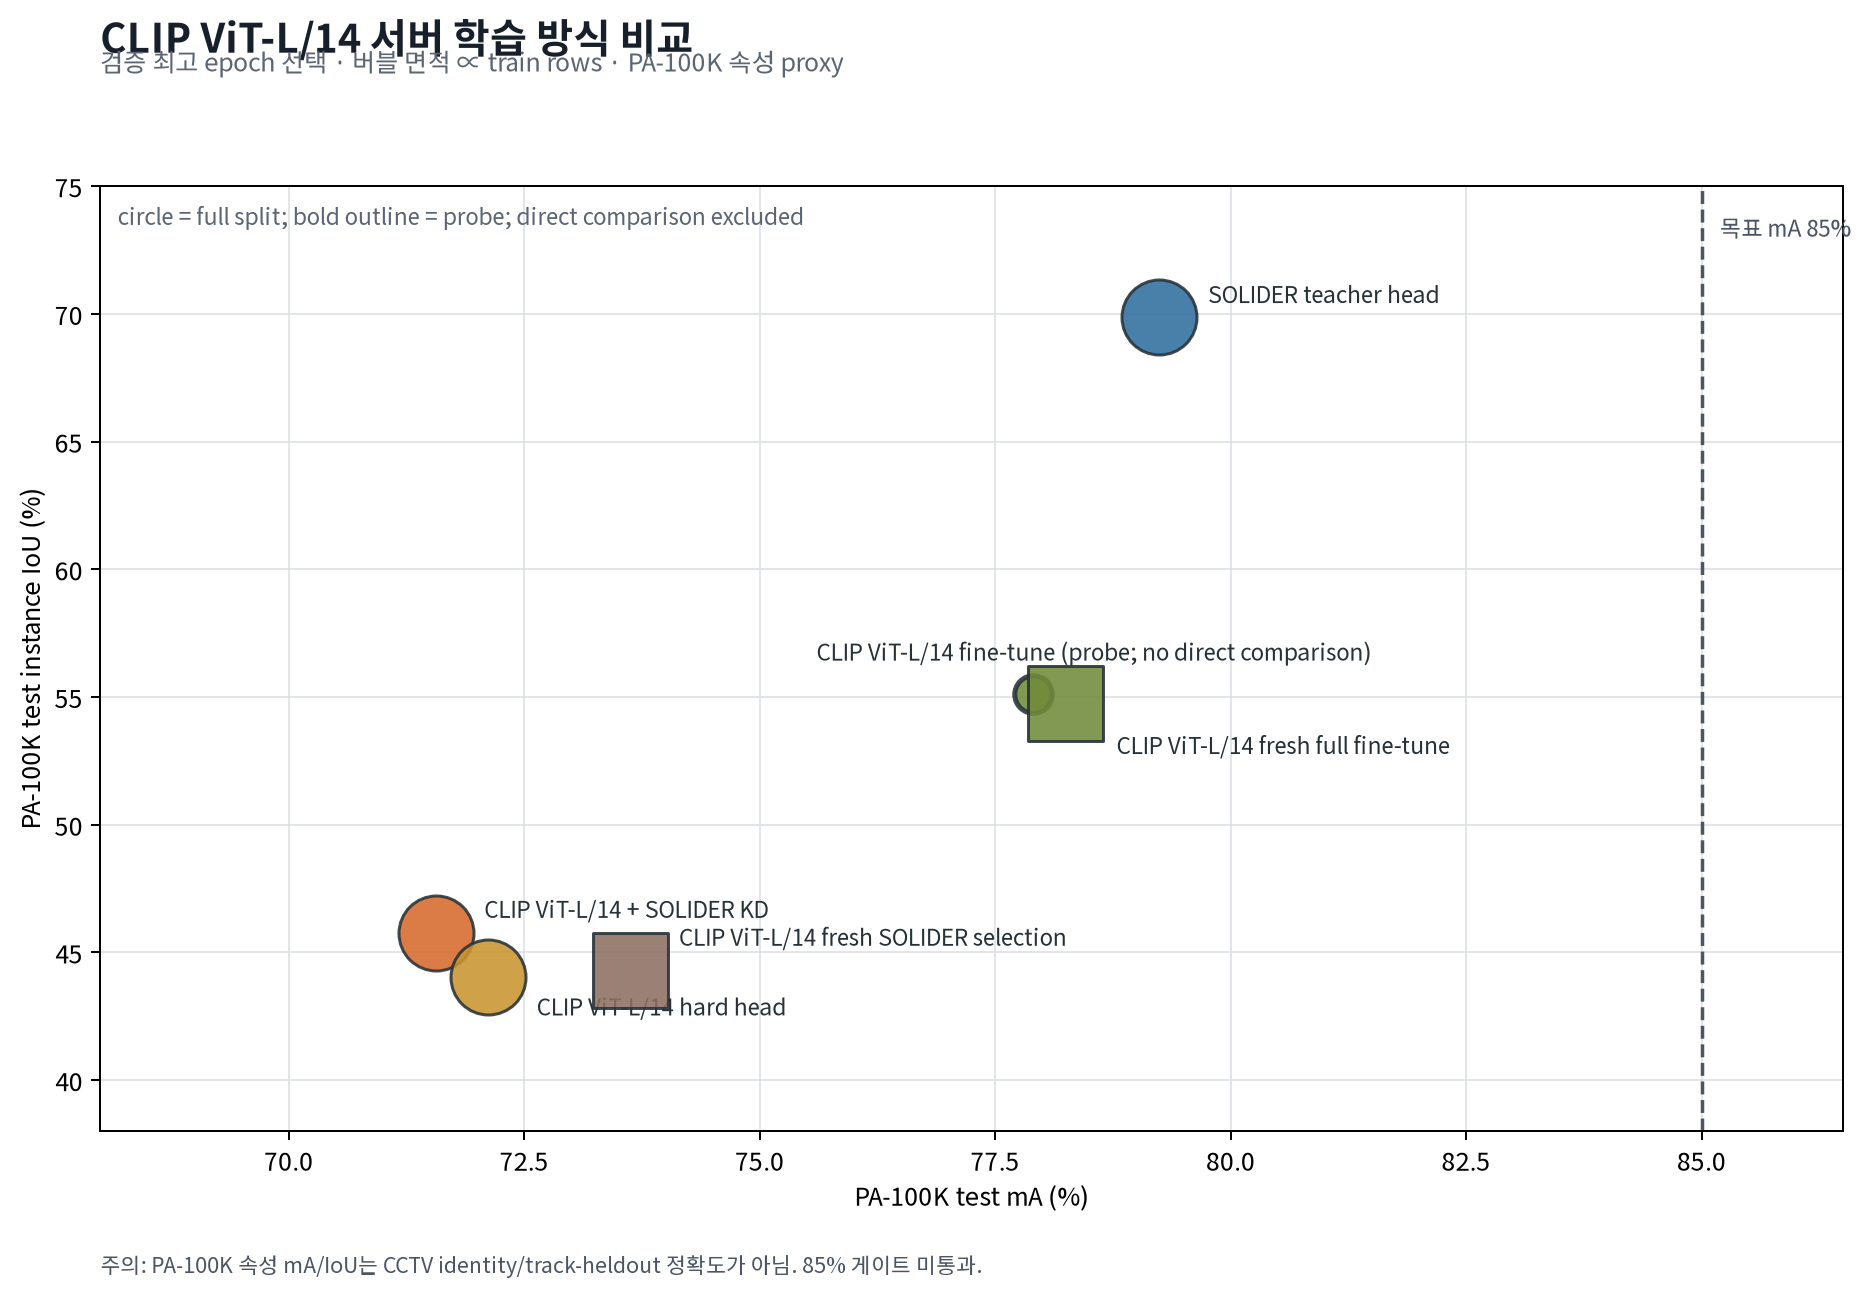

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib import font_manager

out_dir = project_root / 'experiments' / 'results'
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ('Noto Sans CJK KR', 'Noto Sans KR', 'Malgun Gothic', 'NanumGothic'):
    if font_name in available_fonts:
        plt.rcParams['font.family'] = font_name
        break
plt.rcParams['axes.unicode_minus'] = False
colors = {'teacher/reference': '#2f6f9f', 'frozen encoder plus hard labels': '#c9942f', 'frozen encoder plus logit KD': '#d66a2c', 'last-two vision blocks fine-tune': '#718b3a', 'SOLIDER distillation sweep; validation-selected hard head': '#8d6e63'}
markers = {'measured': 'o', 'measured_probe': 'o', 'measured_recheck': 's'}
label_offsets = {
    'CLIP ViT-L/14 fine-tune': (-2.3, 1.6),
    'CLIP ViT-L/14 fresh full fine-tune': (0.55, -1.7),
    'CLIP ViT-L/14 hard head': (0.52, -1.2),
    'CLIP ViT-L/14 fresh SOLIDER selection': (0.52, 1.25),
}
fig, ax = plt.subplots(figsize=(11, 7.5), dpi=180)
fig.subplots_adjust(left=0.10, right=0.98, top=0.84, bottom=0.14)
for row in data['rows']:
    train_ratio = row['train_rows'] / max(r['train_rows'] for r in data['rows'])
    size = 900 * train_ratio
    edge_width = 2.0 if not row['comparable'] else 1.2
    ax.scatter(row['test_mA_pct'], row['test_instance_iou_pct'], s=size, color=colors[row['method']], marker=markers[row['status']], alpha=0.88, edgecolor='#263238', linewidth=edge_width, zorder=3)
    dx, dy = label_offsets.get(row['label'], (0.52, 0.9))
    label = row['label'] + (' (probe; no direct comparison)' if not row['comparable'] else '')
    ax.annotate(label, (row['test_mA_pct'], row['test_instance_iou_pct']), xytext=(row['test_mA_pct'] + dx, row['test_instance_iou_pct'] + dy), fontsize=9, color='#263238', va='center')
ax.axvline(data['target_mA_pct'], color='#4b5563', linestyle='--', linewidth=1.4, zorder=1)
ax.text(data['target_mA_pct'] + 0.2, 73.8, '목표 mA 85%', color='#4b5563', fontsize=9, va='top')
ax.set_xlim(68, 86.5); ax.set_ylim(38, 75)
ax.set_xlabel('PA-100K test mA (%)'); ax.set_ylabel('PA-100K test instance IoU (%)')
ax.grid(True, color='#d9dee5', linewidth=0.8, alpha=0.75); ax.set_axisbelow(True)
ax.text(0.01, 0.98, 'circle = full split; bold outline = probe; direct comparison excluded', transform=ax.transAxes, ha='left', va='top', fontsize=9, color='#5b6573')
fig.suptitle('CLIP ViT-L/14 서버 학습 방식 비교', x=0.10, y=0.965, ha='left', fontsize=16, fontweight='bold', color='#17202a')
fig.text(0.10, 0.925, '검증 최고 epoch 선택 · 버블 면적 ∝ train rows · PA-100K 속성 proxy', fontsize=10, color='#5b6573')
fig.text(0.10, 0.035, '주의: PA-100K 속성 mA/IoU는 CCTV identity/track-heldout 정확도가 아님. 85% 게이트 미통과.', fontsize=8.5, color='#4b5563')
fig.savefig(out_dir / 'clip_vitl14_server_bubble.png', bbox_inches='tight')
fig.savefig(out_dir / 'clip_vitl14_server_bubble.svg', bbox_inches='tight')
plt.show()

## Takeaways

- CLIP ViT-L/14 fine-tune probe는 77.91%를 관측했지만, full split 결과와 직접 우열 비교하지 않는다.
- SOLIDER teacher head는 full split에서 mA 79.24%였지만, 이것도 85%에 미달한다.
- KD는 hard head보다 낮아 현재 학생 모델 승격 근거가 아니다.
- 다음 승격 기준은 실제 CCTV identity/track-heldout 평가다.